In [2]:
import os, glob

INPUT = "/kaggle/input"

for ds in sorted(os.listdir(INPUT)):
    ROOT = os.path.join(INPUT, ds)
    print("\n" + "#" * 70)
    print("DATASET :", ds)
    print("#" * 70)

    # Arborescence (4 niveaux max, 3 exemples de fichiers par dossier)
    for dirpath, dirnames, filenames in os.walk(ROOT):
        depth = dirpath.replace(ROOT, "").count(os.sep)
        if depth > 4:
            continue
        print("  " * depth + os.path.basename(dirpath) + f"/  ({len(filenames)} fichiers)")
        for f in sorted(filenames)[:3]:
            print("  " * (depth + 1) + f)

    # Fichiers de configuration YOLO (noms des classes)
    for y in glob.glob(f"{ROOT}/**/*.yaml", recursive=True):
        print("\n===== YAML :", y)
        print(open(y).read())

    # Exemple de contenu d'un fichier label
    txts = [t for t in glob.glob(f"{ROOT}/**/*.txt", recursive=True)
            if "label" in t.lower()]
    if txts:
        print("\n===== Exemple de label :", txts[0])
        print(open(txts[0]).read()[:300])

    # Nombre total d'images
    imgs = [p for p in glob.glob(f"{ROOT}/**/*", recursive=True)
            if p.lower().endswith((".jpg", ".jpeg", ".png"))]
    print(f"\n>>> Total images : {len(imgs)}")


######################################################################
DATASET : datasets
######################################################################
datasets/  (0 fichiers)
  hayatwaldi2/  (0 fichiers)
    banana-extra/  (0 fichiers)
      test/  (0 fichiers)
        banane_mure/  (32 fichiers)
          web_Cavendish_Ripe_Bottom_0020.jpg
          web_Cavendish_Ripe_Bottom_0024.jpg
          web_Cavendish_Ripe_Left_0020.jpg
        banane_non_mure/  (32 fichiers)
          web_Cavendish_Unripe_Bottom_0006.jpg
          web_Cavendish_Unripe_Left_0006.jpg
          web_Cavendish_Unripe_Right_0006.jpg
        banane_trop_mure/  (32 fichiers)
          web_Cavendish_Overripe_Bottom_0001.jpg
          web_Cavendish_Overripe_Bottom_0004.jpg
          web_Cavendish_Overripe_Bottom_0010.jpg
      train/  (0 fichiers)
        banane_mure/  (144 fichiers)
          web_Cavendish_Ripe_Bottom_0001.jpg
          web_Cavendish_Ripe_Bottom_0006.jpg
          web_Cavendish_Ripe_Bottom_00


 FRAISES/AVOCATS
Images : 760 | Labels : 1332 | Paires image+label : 758
Répartition des images par dossier : {'images': 758, 'yolov5/data/images': 2}
Boîtes par classe : {0: 112, 1: 79, 2: 69, 3: 88, 4: 156, 5: 112, 6: 48, 7: 260}
Nombre de boîtes par image : {1: 708, 2: 17, 3: 7, 4: 5, 5: 6, 6: 7, 7: 2, 8: 3, 9: 1, 10: 1, 12: 1}
  classe 0 → ex. ['IMG_1190.jpg', 'IMG_1191.jpg', 'IMG_1192.jpg']
  classe 1 → ex. ['IMG_1214.jpg', 'IMG_1214.jpg', 'IMG_1217.jpg']
  classe 2 → ex. ['IMG_1215.jpg', 'IMG_1215.jpg', 'IMG_1216.jpg']
  classe 3 → ex. ['IMG_1312.jpg', 'IMG_1314.jpg', 'IMG_813.jpg']
  classe 4 → ex. ['IMG_1000.jpg', 'IMG_1001.jpg', 'IMG_1002.jpg']
  classe 5 → ex. ['IMG_1048.jpg', 'IMG_1049.jpg', 'IMG_1050.jpg']
  classe 6 → ex. ['IMG_1186.jpg', 'IMG_1187.jpg', 'IMG_1188.jpg']
  classe 7 → ex. ['IMG_1082.jpg', 'IMG_1083.jpg', 'IMG_1084.jpg']


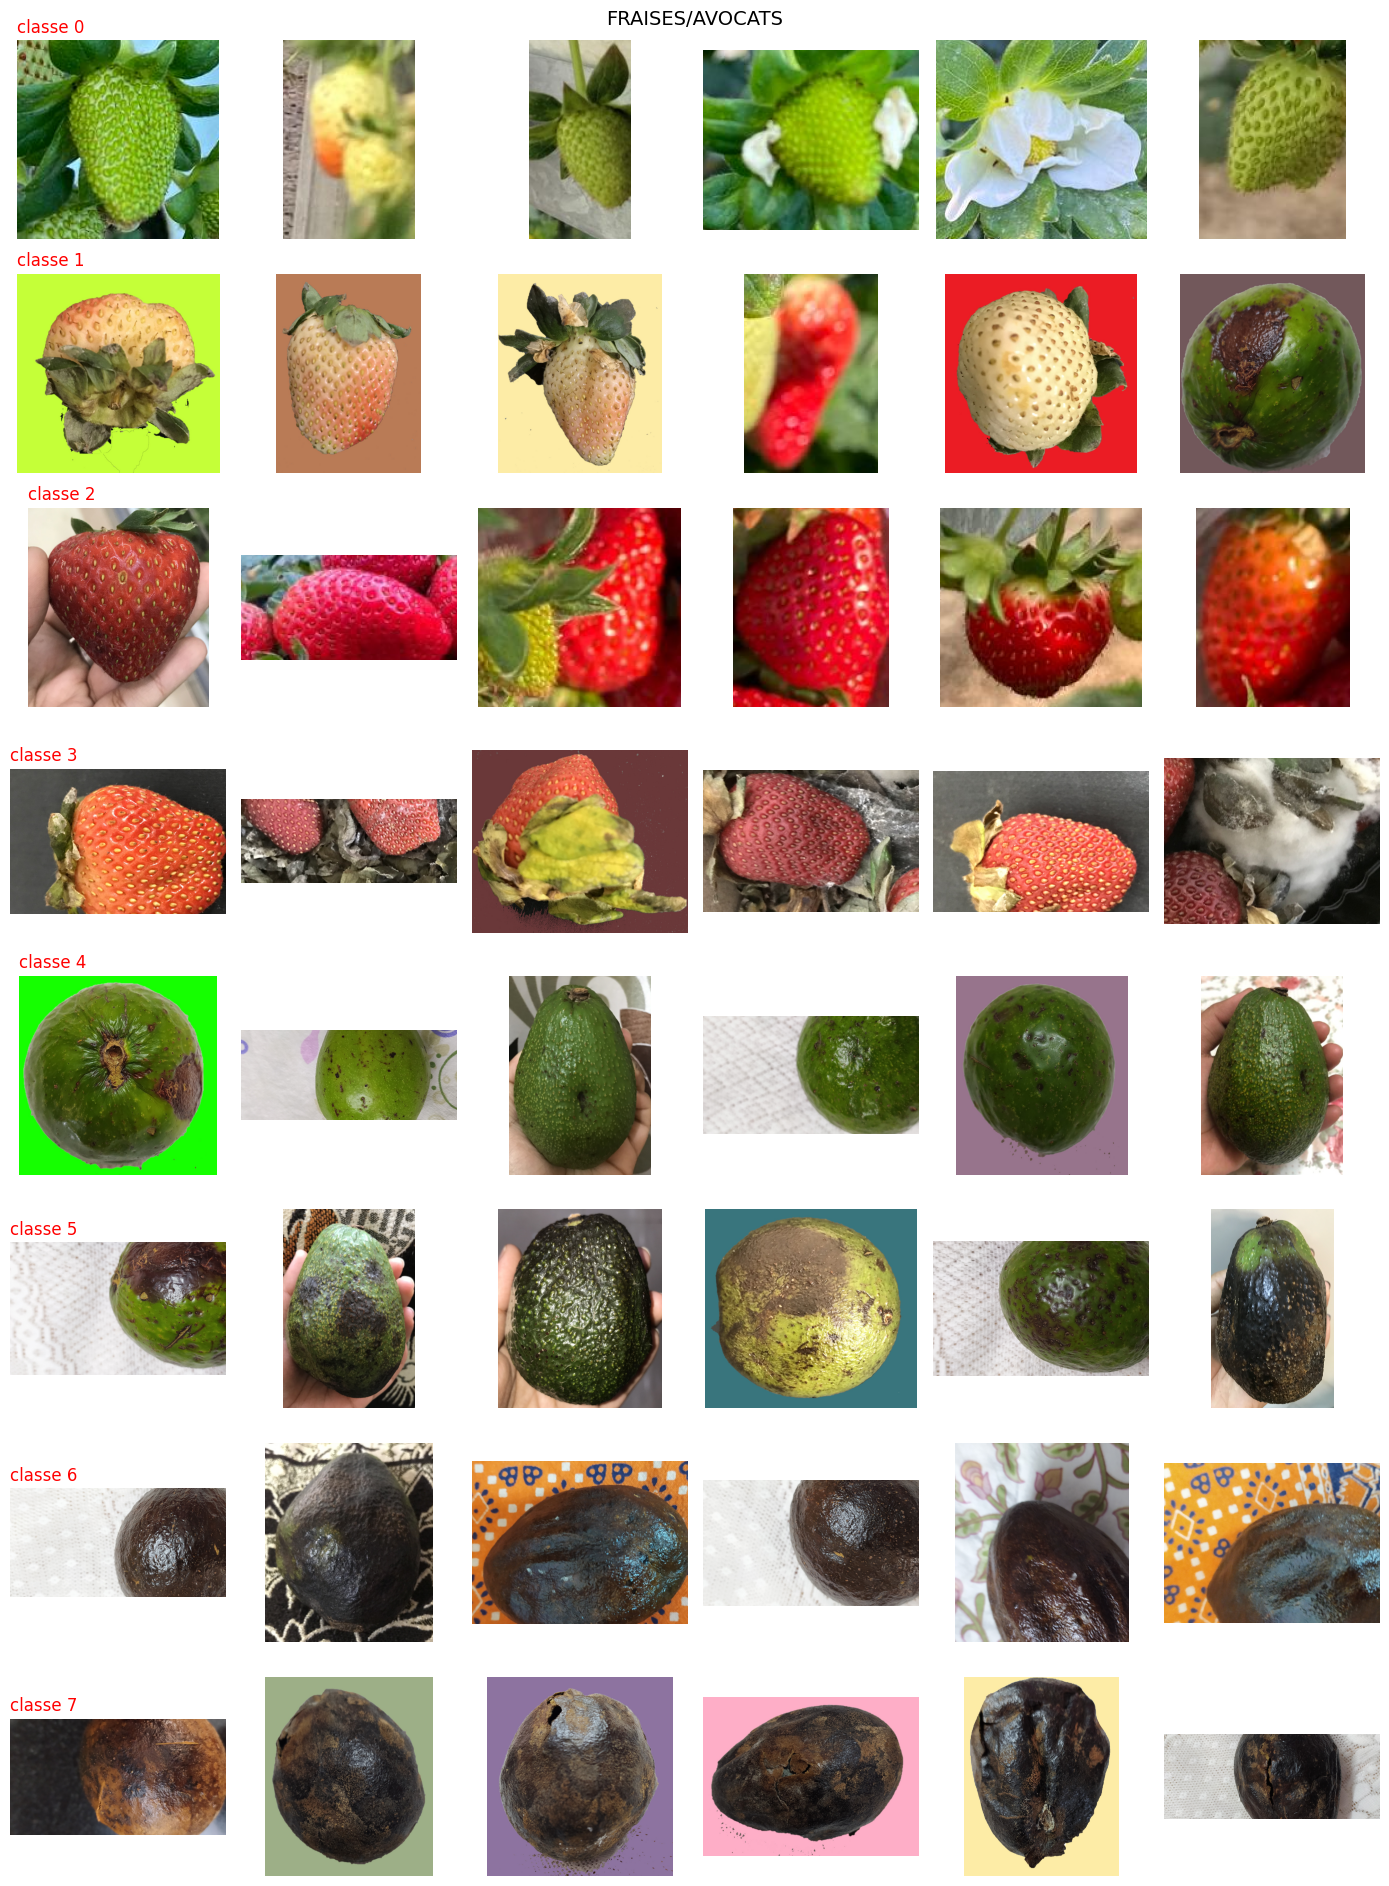


 BANANES
Images : 673 | Labels : 673 | Paires image+label : 673
Répartition des images par dossier : {'images/test': 68, 'images/train': 538, 'images/val': 67}
Boîtes par classe : {0: 220, 1: 205, 2: 249}
Nombre de boîtes par image : {1: 672, 2: 1}
  classe 0 → ex. ['unripe_002.jpg', 'unripe_006.jpg', 'unripe_012.jpg']
  classe 1 → ex. ['overripe_250.jpg', 'ripe_027.jpg', 'ripe_037.jpg']
  classe 2 → ex. ['overripe_003.jpg', 'overripe_013.jpg', 'overripe_025.jpg']


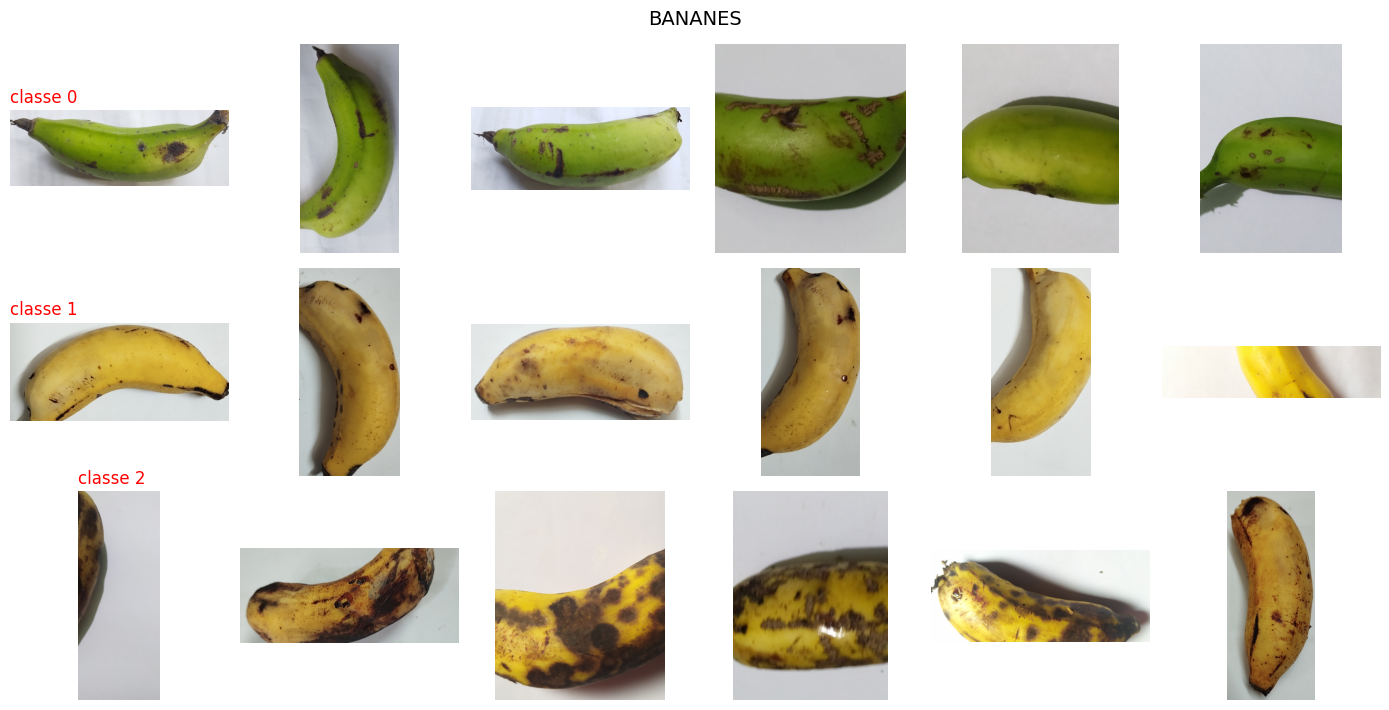

In [3]:
import os, glob, collections, random
from PIL import Image
import matplotlib.pyplot as plt

SA = "/kaggle/input/datasets/hayatwaldi2/strawberry-avocado-ripeness/Comprehensive Dataset on Ripening Stages of Strawberries and Avocados From Unripe to Rotten"
BA = "/kaggle/input/datasets/hayatwaldi2/banana-ripeness/BANANA_DATASET"

def find_images(root):
    return {os.path.splitext(os.path.basename(p))[0]: p
            for p in glob.glob(f"{root}/**/*", recursive=True)
            if p.lower().endswith((".jpg", ".jpeg", ".png"))}

def read_boxes(txt):
    boxes = []
    for line in open(txt):
        parts = line.split()
        if len(parts) == 5:
            boxes.append((int(parts[0]), *map(float, parts[1:])))
    return boxes

def crop(img_path, box, margin=0.05):
    im = Image.open(img_path).convert("RGB")
    W, H = im.size
    _, xc, yc, w, h = box
    w, h = w * (1 + margin), h * (1 + margin)
    return im.crop((max(0, (xc - w/2) * W), max(0, (yc - h/2) * H),
                    min(W, (xc + w/2) * W), min(H, (yc + h/2) * H)))

for name, root in [("FRAISES/AVOCATS", SA), ("BANANES", BA)]:
    print("\n" + "=" * 60, "\n", name)
    imgs = find_images(root)
    labels = glob.glob(f"{root}/labels/**/*.txt", recursive=True)
    pairs = [(imgs[os.path.splitext(os.path.basename(t))[0]], t)
             for t in labels if os.path.splitext(os.path.basename(t))[0] in imgs]
    print(f"Images : {len(imgs)} | Labels : {len(labels)} | Paires image+label : {len(pairs)}")

    # Sous-dossiers (train/val/test ?)
    subdirs = collections.Counter(os.path.relpath(os.path.dirname(p), root) for p in imgs.values())
    print("Répartition des images par dossier :", dict(subdirs))

    # Nombre de boîtes par classe et par image
    cls_count, boxes_per_img, examples = collections.Counter(), collections.Counter(), collections.defaultdict(list)
    for img, t in pairs:
        bx = read_boxes(t)
        boxes_per_img[len(bx)] += 1
        for b in bx:
            cls_count[b[0]] += 1
            examples[b[0]].append((img, b))
    print("Boîtes par classe :", dict(sorted(cls_count.items())))
    print("Nombre de boîtes par image :", dict(sorted(boxes_per_img.items())))

    # Exemples de noms de fichiers par classe (utile pour les bananes)
    for c in sorted(examples):
        print(f"  classe {c} → ex. {[os.path.basename(e[0]) for e in examples[c][:3]]}")

    # Grille visuelle : 6 exemples découpés par classe
    classes = sorted(examples)
    fig, axes = plt.subplots(len(classes), 6, figsize=(14, 2.4 * len(classes)))
    if len(classes) == 1:
        axes = [axes]
    for row, c in enumerate(classes):
        for col, (img, b) in enumerate(random.sample(examples[c], min(6, len(examples[c])))):
            axes[row][col].imshow(crop(img, b))
        for ax in axes[row]:
            ax.axis("off")
        axes[row][0].set_title(f"classe {c}", loc="left", fontsize=12, color="red")
    plt.suptitle(name, fontsize=14)
    plt.tight_layout()
    plt.show()

In [4]:
import os, glob, random, shutil, collections
from PIL import Image
from sklearn.model_selection import train_test_split

SA = "/kaggle/input/datasets/hayatwaldi2/strawberry-avocado-ripeness/Comprehensive Dataset on Ripening Stages of Strawberries and Avocados From Unripe to Rotten"
BA = "/kaggle/input/datasets/hayatwaldi2/banana-ripeness/BANANA_DATASET"
OUT = "/kaggle/working/dataset"
SEED = 42
MIN_SIZE = 40      # ignore les boîtes trop petites (en pixels)
MARGIN = 0.05      # petite marge autour du fruit

SOURCES = [
    (SA, {0: "fraise_non_mure", 1: "fraise_partiellement_mure", 2: "fraise_mure", 3: "fraise_pourrie",
          4: "avocat_non_mur", 5: "avocat_partiellement_mur", 6: "avocat_mur", 7: "avocat_pourri"}),
    (BA, {0: "banane_non_mure", 1: "banane_mure", 2: "banane_trop_mure"}),
]

def find_images(root):
    return {os.path.splitext(os.path.basename(p))[0]: p
            for p in glob.glob(f"{root}/**/*", recursive=True)
            if p.lower().endswith((".jpg", ".jpeg", ".png")) and "yolov5" not in p}

def read_boxes(txt):
    out = []
    for line in open(txt):
        p = line.split()
        if len(p) == 5:
            out.append((int(p[0]), *map(float, p[1:])))
    return out

# 1) Liste des photos d'origine avec leurs boîtes
photos = []   # (chemin_image, [(classe_nom, box), ...], classe_majoritaire)
for root, mapping in SOURCES:
    imgs = find_images(root)
    for t in glob.glob(f"{root}/labels/**/*.txt", recursive=True):
        stem = os.path.splitext(os.path.basename(t))[0]
        if stem not in imgs:
            continue
        boxes = [(mapping[b[0]], b) for b in read_boxes(t) if b[0] in mapping]
        if boxes:
            major = collections.Counter(c for c, _ in boxes).most_common(1)[0][0]
            photos.append((imgs[stem], boxes, major))
print("Photos d'origine :", len(photos))

# 2) Découpage 70/15/15 PAR PHOTO (évite les fuites entre train et test)
labels = [p[2] for p in photos]
train, temp = train_test_split(photos, test_size=0.30, stratify=labels, random_state=SEED)
val, test = train_test_split(temp, test_size=0.50, stratify=[p[2] for p in temp], random_state=SEED)

# 3) Découpe des fruits et sauvegarde
if os.path.exists(OUT):
    shutil.rmtree(OUT)
counts = collections.defaultdict(collections.Counter)
for split, items in [("train", train), ("val", val), ("test", test)]:
    for img_path, boxes, _ in items:
        im = Image.open(img_path).convert("RGB")
        W, H = im.size
        base = os.path.splitext(os.path.basename(img_path))[0]
        for i, (cls, (_, xc, yc, w, h)) in enumerate(boxes):
            w, h = w * (1 + MARGIN), h * (1 + MARGIN)
            x1, y1 = max(0, (xc - w/2) * W), max(0, (yc - h/2) * H)
            x2, y2 = min(W, (xc + w/2) * W), min(H, (yc + h/2) * H)
            if (x2 - x1) < MIN_SIZE or (y2 - y1) < MIN_SIZE:
                continue
            crop = im.crop((x1, y1, x2, y2))
            crop.thumbnail((400, 400))          # réduit la taille disque
            d = os.path.join(OUT, split, cls)
            os.makedirs(d, exist_ok=True)
            crop.save(os.path.join(d, f"{base}_{i}.jpg"), quality=95)
            counts[split][cls] += 1

# 4) Récapitulatif
classes = sorted({c for s in counts.values() for c in s})
print(f"\n{'classe':28s} {'train':>6s} {'val':>6s} {'test':>6s}")
for c in classes:
    print(f"{c:28s} {counts['train'][c]:6d} {counts['val'][c]:6d} {counts['test'][c]:6d}")
print(f"{'TOTAL':28s} {sum(counts['train'].values()):6d} {sum(counts['val'].values()):6d} {sum(counts['test'].values()):6d}")

Photos d'origine : 1431

classe                        train    val   test
avocat_mur                       33      7      8
avocat_non_mur                  109     24     23
avocat_partiellement_mur         78     17     17
avocat_pourri                   182     39     39
banane_mure                     144     30     31
banane_non_mure                 154     33     33
banane_trop_mure                174     38     37
fraise_mure                      48     10     11
fraise_non_mure                  73     25     14
fraise_partiellement_mure        55     12     12
fraise_pourrie                   68     14      6
TOTAL                          1118    249    231


#### 1-Chargement des données

In [5]:
import os, numpy as np, tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight

DATA = "/kaggle/working/dataset"
IMG = (224, 224)
BATCH = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    f"{DATA}/train", image_size=IMG, batch_size=BATCH, seed=SEED, shuffle=True)
val_ds = tf.keras.utils.image_dataset_from_directory(
    f"{DATA}/val", image_size=IMG, batch_size=BATCH, shuffle=False)
test_ds = tf.keras.utils.image_dataset_from_directory(
    f"{DATA}/test", image_size=IMG, batch_size=BATCH, shuffle=False)

CLASSES = train_ds.class_names
N = len(CLASSES)
print(N, "classes :", CLASSES)

# Poids par classe : les classes rares comptent plus dans la perte
y_train = np.concatenate([y.numpy() for _, y in train_ds])
weights = compute_class_weight("balanced", classes=np.arange(N), y=y_train)
CLASS_WEIGHT = dict(enumerate(weights))
for c, w in zip(CLASSES, weights):
    print(f"  {c:28s} poids = {w:.2f}")

TEST_FILES = test_ds.file_paths      # ← AVANT le prefetch

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

Found 1118 files belonging to 11 classes.


I0000 00:00:1792886319.600912      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792886319.604723      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 249 files belonging to 11 classes.
Found 231 files belonging to 11 classes.
11 classes : ['avocat_mur', 'avocat_non_mur', 'avocat_partiellement_mur', 'avocat_pourri', 'banane_mure', 'banane_non_mure', 'banane_trop_mure', 'fraise_mure', 'fraise_non_mure', 'fraise_partiellement_mure', 'fraise_pourrie']
  avocat_mur                   poids = 3.08
  avocat_non_mur               poids = 0.93
  avocat_partiellement_mur     poids = 1.30
  avocat_pourri                poids = 0.56
  banane_mure                  poids = 0.71
  banane_non_mure              poids = 0.66
  banane_trop_mure             poids = 0.58
  fraise_mure                  poids = 2.12
  fraise_non_mure              poids = 1.39
  fraise_partiellement_mure    poids = 1.85
  fraise_pourrie               poids = 1.49


In [6]:
import os, glob, shutil
EXTRA = glob.glob("/kaggle/input/**/banana-extra", recursive=True) or ["/kaggle/input/banana-extra"]
EXTRA = EXTRA[0]
n = 0
for split in ("train", "val", "test"):
    for f in glob.glob(f"{EXTRA}/**/{split}/*/*.jpg", recursive=True):
        cls = os.path.basename(os.path.dirname(f))
        dest = f"/kaggle/working/dataset/{split}/{cls}"
        os.makedirs(dest, exist_ok=True)
        shutil.copy(f, dest); n += 1
print(n, "images ajoutées")   # attendu : 636

624 images ajoutées


In [7]:
import os, glob, shutil
EXTRA = "/kaggle/input/datasets/hayatwaldi2/banana-extra"
n = 0
for split in ("train", "val", "test"):
    for f in glob.glob(f"{EXTRA}/{split}/*/*.jpg"):
        cls = os.path.basename(os.path.dirname(f))
        dest = f"/kaggle/working/dataset/{split}/{cls}"
        os.makedirs(dest, exist_ok=True)
        shutil.copy(f, dest); n += 1
print(n, "images ajoutées")   # attendu : 624

for split in ("train", "val", "test"):
    files = glob.glob(f"/kaggle/working/dataset/{split}/*/*.jpg")
    web = [f for f in files if "web_" in os.path.basename(f)]
    print(f"{split:5s}: {len(files)} images dont {len(web)} web_")

624 images ajoutées
train: 1550 images dont 432 web_
val  : 345 images dont 96 web_
test : 327 images dont 96 web_


In [8]:
import os, glob, collections
for split in ("train", "val", "test"):
    files = glob.glob(f"/kaggle/working/dataset/{split}/*/*.jpg")
    web = [f for f in files if "web_" in os.path.basename(f)]
    print(f"{split:5s}: {len(files)} images dont {len(web)} avec le préfixe web_")
    c = collections.Counter(os.path.basename(os.path.dirname(f)) for f in web)
    print("       web_ par classe :", dict(c))

print("\nContenu du dataset banana-extra :")
for root, dirs, files in os.walk("/kaggle/input"):
    if "banana-extra" in root or "banana_extra" in root:
        depth = root.count(os.sep)
        if depth < 9:
            print(root, f"({len(files)} fichiers)")

train: 1550 images dont 432 avec le préfixe web_
       web_ par classe : {'banane_trop_mure': 144, 'banane_non_mure': 144, 'banane_mure': 144}
val  : 345 images dont 96 avec le préfixe web_
       web_ par classe : {'banane_trop_mure': 32, 'banane_non_mure': 32, 'banane_mure': 32}
test : 327 images dont 96 avec le préfixe web_
       web_ par classe : {'banane_trop_mure': 32, 'banane_non_mure': 32, 'banane_mure': 32}

Contenu du dataset banana-extra :
/kaggle/input/datasets/hayatwaldi2/banana-extra (0 fichiers)
/kaggle/input/datasets/hayatwaldi2/banana-extra/test (0 fichiers)
/kaggle/input/datasets/hayatwaldi2/banana-extra/test/banane_mure (32 fichiers)
/kaggle/input/datasets/hayatwaldi2/banana-extra/test/banane_non_mure (32 fichiers)
/kaggle/input/datasets/hayatwaldi2/banana-extra/test/banane_trop_mure (32 fichiers)
/kaggle/input/datasets/hayatwaldi2/banana-extra/train (0 fichiers)
/kaggle/input/datasets/hayatwaldi2/banana-extra/train/banane_mure (144 fichiers)
/kaggle/input/datasets

#### 2 - Construction du modèle MobileNetV2

In [9]:
# Augmentation renforcée : PAS de changement de teinte (la couleur = la maturité)
augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom((-0.3, 0.1)),        # zoom avant jusqu'à 30 %
    tf.keras.layers.RandomTranslation(0.1, 0.1),
    tf.keras.layers.RandomBrightness(0.2),
    tf.keras.layers.RandomContrast(0.2),
], name="augmentation")

base = tf.keras.applications.MobileNetV2(
    input_shape=IMG + (3,), include_top=False, weights="imagenet")
base.trainable = False   # Phase 1 : backbone gelé

inputs = tf.keras.Input(shape=IMG + (3,))            # pixels 0-255
x = augment(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)  # → [-1, 1]
x = tf.keras.layers.GaussianNoise(0.05)(x)           # bruit léger, actif seulement à l'entraînement
x = base(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.4)(x)
outputs = tf.keras.layers.Dense(N, activation="softmax")(x)
model = tf.keras.Model(inputs, outputs)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gaussian_noise (GaussianNoise)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 11)             │        14,091 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,272,075 (8.67 MB)

 Trainable params: 14,091 (55.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

#### 3 - Phase 1, entraînement de la tête seule

In [10]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3),
]

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])

hist1 = model.fit(train_ds, validation_data=val_ds, epochs=20,
                  class_weight=CLASS_WEIGHT, callbacks=callbacks)

Epoch 1/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 14s 134ms/step - accuracy: 0.3757 - loss: 2.0113 - val_accuracy: 0.7309 - val_loss: 0.9287 - learning_rate: 0.0010
Epoch 2/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 69ms/step - accuracy: 0.6646 - loss: 1.0244 - val_accuracy: 0.8313 - val_loss: 0.5964 - learning_rate: 0.0010
Epoch 3/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 69ms/step - accuracy: 0.7317 - loss: 0.8144 - val_accuracy: 0.8594 - val_loss: 0.5001 - learning_rate: 0.0010
Epoch 4/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 69ms/step - accuracy: 0.8014 - loss: 0.6624 - val_accuracy: 0.8715 - val_loss: 0.4579 - learning_rate: 0.0010
Epoch 5/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 67ms/step - accuracy: 0.8041 - loss: 0.6166 - val_accuracy: 0.8594 - val_loss: 0.4316 - learning_rate: 0.0010
Epoch 6/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 67ms/step - accuracy: 0.8256 - loss: 0.5554 - val_accuracy: 0.8554 - val_loss: 0.3925 - learning_rate: 0.0010
Epoch 7/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 67ms/step - accuracy: 0.8497 - loss: 0.4949 - val_a

In [11]:
cb1 = [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
       tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3)]
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist1 = model.fit(train_ds, validation_data=val_ds, epochs=25,
                  class_weight=CLASS_WEIGHT, callbacks=cb1)

Epoch 1/25
35/35 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - accuracy: 0.8730 - loss: 0.4103 - val_accuracy: 0.8675 - val_loss: 0.3545 - learning_rate: 0.0010
Epoch 2/25
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 68ms/step - accuracy: 0.8560 - loss: 0.4319 - val_accuracy: 0.8755 - val_loss: 0.3591 - learning_rate: 0.0010
Epoch 3/25
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 70ms/step - accuracy: 0.8676 - loss: 0.3974 - val_accuracy: 0.8635 - val_loss: 0.3322 - learning_rate: 0.0010
Epoch 4/25
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 71ms/step - accuracy: 0.8980 - loss: 0.3404 - val_accuracy: 0.8956 - val_loss: 0.3275 - learning_rate: 0.0010
Epoch 5/25
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 68ms/step - accuracy: 0.8962 - loss: 0.3456 - val_accuracy: 0.8594 - val_loss: 0.3310 - learning_rate: 0.0010
Epoch 6/25
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 71ms/step - accuracy: 0.8945 - loss: 0.3280 - val_accuracy: 0.8916 - val_loss: 0.3252 - learning_rate: 0.0010
Epoch 7/25
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 69ms/step - accuracy: 0.8989 - loss: 0.3229 - val_ac

#### 4 - Phase 2, fine-tuning

In [21]:
base.trainable = True
FREEZE_UNTIL = len(base.layers) - 60
for i, layer in enumerate(base.layers):
    layer.trainable = (i >= FREEZE_UNTIL) and not isinstance(layer, tf.keras.layers.BatchNormalization)

cb2 = [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
       tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-7)]
model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist2 = model.fit(train_ds, validation_data=val_ds, epochs=40,
                  class_weight=CLASS_WEIGHT, callbacks=cb2, verbose=2)
model.save("/kaggle/working/fruit_ripeness_v2.keras")

Epoch 1/40
35/35 - 11s - 311ms/step - accuracy: 0.9356 - loss: 0.1850 - val_accuracy: 0.8835 - val_loss: 0.2936 - learning_rate: 1.0000e-05
Epoch 2/40
35/35 - 3s - 90ms/step - accuracy: 0.9526 - loss: 0.1495 - val_accuracy: 0.8916 - val_loss: 0.2728 - learning_rate: 1.0000e-05
Epoch 3/40
35/35 - 3s - 88ms/step - accuracy: 0.9508 - loss: 0.1436 - val_accuracy: 0.8956 - val_loss: 0.2976 - learning_rate: 1.0000e-05
Epoch 4/40
35/35 - 3s - 88ms/step - accuracy: 0.9472 - loss: 0.1663 - val_accuracy: 0.8835 - val_loss: 0.2882 - learning_rate: 1.0000e-05
Epoch 5/40
35/35 - 3s - 88ms/step - accuracy: 0.9571 - loss: 0.1321 - val_accuracy: 0.8876 - val_loss: 0.2832 - learning_rate: 1.0000e-05
Epoch 6/40
35/35 - 3s - 88ms/step - accuracy: 0.9589 - loss: 0.1363 - val_accuracy: 0.8956 - val_loss: 0.2978 - learning_rate: 1.0000e-05
Epoch 7/40
35/35 - 3s - 88ms/step - accuracy: 0.9642 - loss: 0.1223 - val_accuracy: 0.8996 - val_loss: 0.2846 - learning_rate: 5.0000e-06
Epoch 8/40
35/35 - 3s - 88ms/ste

#### 5 - Courbes d’apprentissage

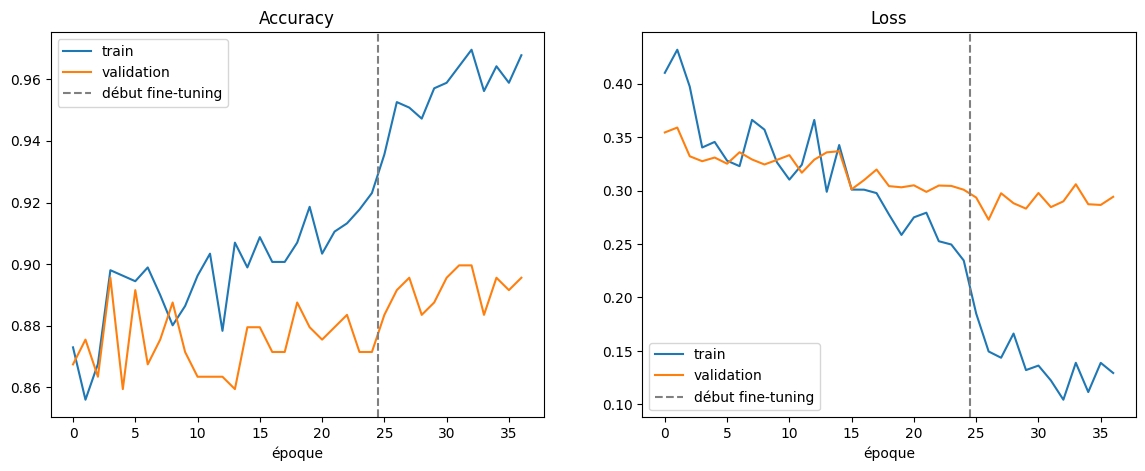

In [23]:
import matplotlib.pyplot as plt

acc = hist1.history["accuracy"] + hist2.history["accuracy"]
val_acc = hist1.history["val_accuracy"] + hist2.history["val_accuracy"]
loss = hist1.history["loss"] + hist2.history["loss"]
val_loss = hist1.history["val_loss"] + hist2.history["val_loss"]
sep = len(hist1.history["accuracy"])

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, (tr, va, title) in zip(ax, [(acc, val_acc, "Accuracy"), (loss, val_loss, "Loss")]):
    a.plot(tr, label="train"); a.plot(va, label="validation")
    a.axvline(sep - 0.5, color="gray", linestyle="--", label="début fine-tuning")
    a.set_title(title); a.set_xlabel("époque"); a.legend()
plt.show()

#### 6 - Évaluation sur le jeu de test

8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 193ms/step
                           precision    recall  f1-score   support

               avocat_mur      1.000     0.625     0.769         8
           avocat_non_mur      1.000     0.783     0.878        23
 avocat_partiellement_mur      0.773     1.000     0.872        17
            avocat_pourri      0.929     1.000     0.963        39
              banane_mure      0.886     1.000     0.939        31
          banane_non_mure      1.000     1.000     1.000        33
         banane_trop_mure      1.000     0.892     0.943        37
              fraise_mure      0.625     0.909     0.741        11
          fraise_non_mure      0.923     0.857     0.889        14
fraise_partiellement_mure      0.889     0.667     0.762        12
           fraise_pourrie      0.800     0.667     0.727         6

                 accuracy                          0.909       231
                macro avg      0.893     0.854     0.862       231
             weighted

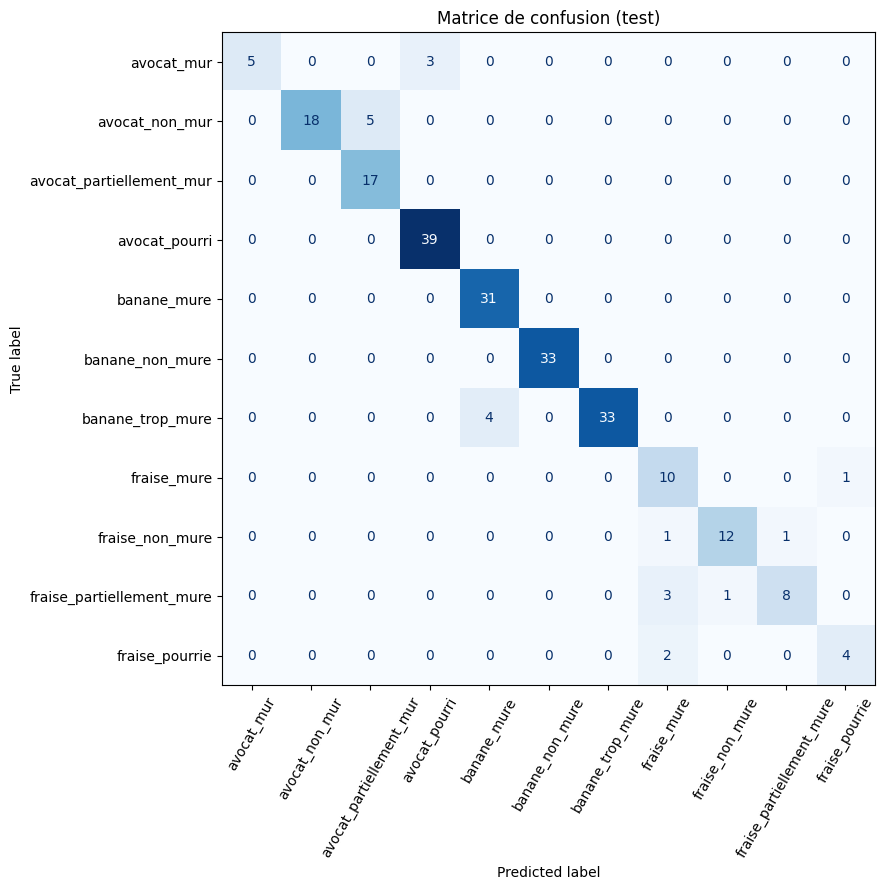

In [24]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = np.argmax(model.predict(test_ds), axis=1)

print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(11, 9))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, xticks_rotation=60, cmap="Blues", colorbar=False)
plt.title("Matrice de confusion (test)")
plt.tight_layout(); plt.show()

In [25]:
web = np.array(["web_" in os.path.basename(f) for f in TEST_FILES])
print(f"Précision globale du test : {np.mean(y_true == y_pred):.1%}  ({len(y_true)} images)")
print(f"  bananes du 2e dataset (web_) : {np.mean(y_true[web] == y_pred[web]):.1%}  ({web.sum()} images)")
print(f"  reste du test                : {np.mean(y_true[~web] == y_pred[~web]):.1%}  ({(~web).sum()} images)")

Précision globale du test : 90.9%  (231 images)
  bananes du 2e dataset (web_) : nan%  (0 images)
  reste du test                : 90.9%  (231 images)


/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [26]:
from sklearn.metrics import confusion_matrix
ib = [CLASSES.index(c) for c in ("banane_non_mure", "banane_mure", "banane_trop_mure")]
isb = np.isin(y_true, ib)
for name, m in (("BananaID (web_)", web & isb), ("Anciennes bananes", ~web & isb)):
    cm = confusion_matrix(y_true[m], y_pred[m], labels=ib)
    print(f"\n{name} — {m.sum()} images, précision {np.mean(y_true[m]==y_pred[m]):.1%}")
    print("lignes = vrai, colonnes = prédit (non mûre, mûre, trop mûre)")
    print(cm)


BananaID (web_) — 0 images, précision nan%
lignes = vrai, colonnes = prédit (non mûre, mûre, trop mûre)
[[0 0 0]
 [0 0 0]
 [0 0 0]]

Anciennes bananes — 101 images, précision 96.0%
lignes = vrai, colonnes = prédit (non mûre, mûre, trop mûre)
[[33  0  0]
 [ 0 31  0]
 [ 0  4 33]]


/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


#### 7 - Export pour le smartphone (TFLite)

In [28]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]   # quantification
tflite = converter.convert()

open("/kaggle/working/fruit_ripeness.tflite", "wb").write(tflite)
open("/kaggle/working/labels.txt", "w").write("\n".join(CLASSES))

print(f"Taille .keras  : {os.path.getsize('/kaggle/working/fruit_ripeness_v2.keras')/1e6:.1f} Mo")
print(f"Taille .tflite : {len(tflite)/1e6:.1f} Mo")

INFO:tensorflow:Assets written to: /tmp/tmpkz545z17/assets


INFO:tensorflow:Assets written to: /tmp/tmpkz545z17/assets


Saved artifact at '/tmp/tmpkz545z17'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_154')
Output Type:
  TensorSpec(shape=(None, 11), dtype=tf.float32, name=None)
Captures:
  139949321172752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139949321173520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139949321172560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139949321173712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139949321171408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139949321173136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139949321174480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139949321174288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139949321174672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139949321172944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139949321

W0000 00:00:1792887432.384378      49 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1792887432.384443      49 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.


#### 8 - vérifier que la quantification n’a pas dégradé la précision

In [29]:
import time

interp = tf.lite.Interpreter(model_path="/kaggle/working/fruit_ripeness.tflite")
interp.allocate_tensors()
inp = interp.get_input_details()[0]
out = interp.get_output_details()[0]

y_true_l, y_pred_l, times = [], [], []
for images, labels in test_ds.unbatch().batch(1):
    interp.set_tensor(inp["index"], images.numpy().astype(np.float32))
    t0 = time.perf_counter()
    interp.invoke()
    times.append(time.perf_counter() - t0)
    y_pred_l.append(np.argmax(interp.get_tensor(out["index"])))
    y_true_l.append(int(labels.numpy()[0]))

acc_tflite = np.mean(np.array(y_true_l) == np.array(y_pred_l))
acc_keras = np.mean(y_true == y_pred)
print(f"Précision Keras  : {acc_keras:.3%}")
print(f"Précision TFLite : {acc_tflite:.3%}")
print(f"Prédictions identiques : {np.mean(np.array(y_pred_l) == y_pred):.1%}")
print(f"Temps moyen par image (CPU Kaggle) : {np.mean(times)*1000:.1f} ms")

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


Précision Keras  : 90.909%
Précision TFLite : 91.342%
Prédictions identiques : 98.7%
Temps moyen par image (CPU Kaggle) : 20.2 ms
